
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of stocks from the S&P 600.  Construct portfolios from the 600 stocks in the S&P 600 small cap index and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['sp600-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='3 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,AAMI,Acadian Asset Management Inc.,US Stocks:Financials,227.48,160.62,141.69,140.30,47.90,26.50,43.02,17.58,37.09,35.13,36.41,47.90,35.13,1.36
1,AAP,"Advance Auto Parts, Inc.",US Stocks:Consumer Discretionary,67.72,42.10,16.54,23.07,-18.20,-18.99,78.49,36.92,48.57,54.80,50.69,-18.20,54.80,-997.36
2,AAT,American Assets Trust,US Stocks:Real Estate,117.49,54.17,24.97,26.11,12.79,-2.75,22.00,8.45,22.71,26.39,27.57,12.79,26.39,0.48
3,ABCB,Ameris Bancorp,US Stocks:Financials,40.37,23.52,38.41,36.53,38.75,8.96,18.35,9.23,15.29,30.23,31.27,38.75,30.23,1.28
4,ABG,Asbury Automotive Group,US Stocks:Consumer Discretionary,-40.56,-35.44,-17.89,-15.22,-3.11,-0.99,39.17,30.30,21.86,32.99,36.28,-3.11,32.99,-102.60
5,ABM,"ABM Industries, Inc.",US Stocks:Industrials,-38.83,-14.89,-23.14,-22.49,-1.47,-2.66,22.95,14.63,23.03,24.46,25.24,-1.47,24.46,-35.96
6,ABR,Arbor Realty Trust,US Stocks:Financials,-64.13,-52.56,-33.50,-35.23,-12.83,-10.20,70.45,59.04,36.95,34.78,37.68,-12.83,34.78,-446.23
7,ACA,"Arcosa, Inc.",US Stocks:Industrials,93.75,42.75,47.57,45.29,22.99,15.61,39.50,21.01,26.02,29.53,28.85,22.99,29.53,0.78
8,ACAD,Acadia Pharmaceuticals,US Stocks:Healthcare,-39.50,-21.13,-1.63,-2.52,-5.34,-0.26,34.66,20.34,29.02,52.24,47.82,-5.34,52.24,-278.96
9,ACHC,Acadia Healthcare,US Stocks:Healthcare,-4.03,96.03,1.98,1.02,-30.47,-17.88,56.39,34.12,81.91,61.40,51.07,-30.47,61.40,-1870.86


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Subclass', num_per_group=1)
rank_filtered = rank
#rank_filtered = rank.loc[(rank['3 mo'] > 0) & rank['1 Yr'] > 0]
rank_filtered = rank_filtered.head(20)
rank_filtered

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
335,MDU,"MDU Resources Group, Inc.",US Stocks:Utilities,10.90,2.03,30.17,29.14,26.68,13.55,17.09,11.23,22.05,24.94,23.91,26.68,24.94,1.07
152,DBD,Diebold Nixdorf,US Stocks:Technology,5.82,60.73,67.64,66.20,67.64,67.64,41.83,19.14,23.09,35.53,35.53,67.64,35.53,1.90
138,CURB,Curbline Properties Corp.,US Stocks:Real Estate,23.48,52.54,33.25,31.46,33.25,33.25,15.97,6.87,18.26,18.13,18.13,33.25,18.13,1.83
107,CENX,Century Aluminum Company,US Stocks:Materials,168.00,436.55,308.99,312.78,100.54,38.94,59.85,31.92,34.36,57.00,68.19,100.54,57.00,1.76
24,AGX,"Argan, Inc.",US Stocks:Industrials,378.96,220.62,219.94,223.66,154.42,72.26,51.17,33.07,49.82,44.91,40.09,154.42,44.91,3.44
214,FTRE,Fortrea,US Stocks:Healthcare,324.79,45.02,268.18,261.45,268.18,268.18,86.22,21.39,93.29,80.88,80.88,268.18,80.88,3.32
498,SNEX,StoneX Group Inc.,US Stocks:Financials,216.24,263.98,96.95,91.71,65.44,40.69,55.85,20.12,36.15,30.38,32.57,65.44,30.38,2.15
288,KGS,"Kodiak Gas Services, Inc.",US Stocks:Energy,131.32,276.83,96.68,105.34,96.68,96.68,45.21,20.19,34.82,33.42,33.42,96.68,33.42,2.89
435,PSMT,PriceSmart,US Stocks:Consumer Staples,46.09,84.63,61.04,61.79,34.17,16.03,24.27,13.06,22.07,24.16,25.97,34.17,24.16,1.41
412,PHIN,"PHINIA, Inc.",US Stocks:Consumer Discretionary,30.28,99.69,79.66,78.86,79.66,79.66,36.31,22.48,27.81,33.09,33.09,79.66,33.09,2.41


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# everything ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank_filtered['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

# top 10
top10_portfolio = {
    'Title': 'Ranked Portfolio'
}
top10 = list(rank_filtered['Investment Option'])[:10]
top10_portfolio.update(dict.fromkeys(top10, 1/len(top10)))

### Custom Portfolios

In [8]:
# My portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = ranked_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}
#weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,MDU,DBD,CURB,CENX,AGX,FTRE,SNEX,KGS,PSMT,PHIN,SPHR,Ranked Portfolio
Annual Returns,26.68,67.64,33.25,100.54,154.42,268.18,65.44,96.68,34.17,79.66,78.77,76.95
Std Dev,24.94,35.53,18.13,57.00,44.91,80.88,30.38,33.42,24.16,33.09,58.75,21.71
Sharpe Ratio,1.07,1.90,1.83,1.76,3.44,3.32,2.15,2.89,1.41,2.41,1.34,3.54
Weight,0.15,0.09,0.17,0.05,0.05,0.08,0.08,0.08,0.13,0.07,0.06,1.00
Worst Typical Down Year,-23.20,-3.42,-3.01,-13.46,64.60,106.42,4.68,29.84,-14.15,13.48,-38.73,33.53
Black Swan,-48.14,-38.95,-21.14,-70.46,19.69,25.54,-25.70,-3.58,-38.31,-19.61,-97.48,11.82


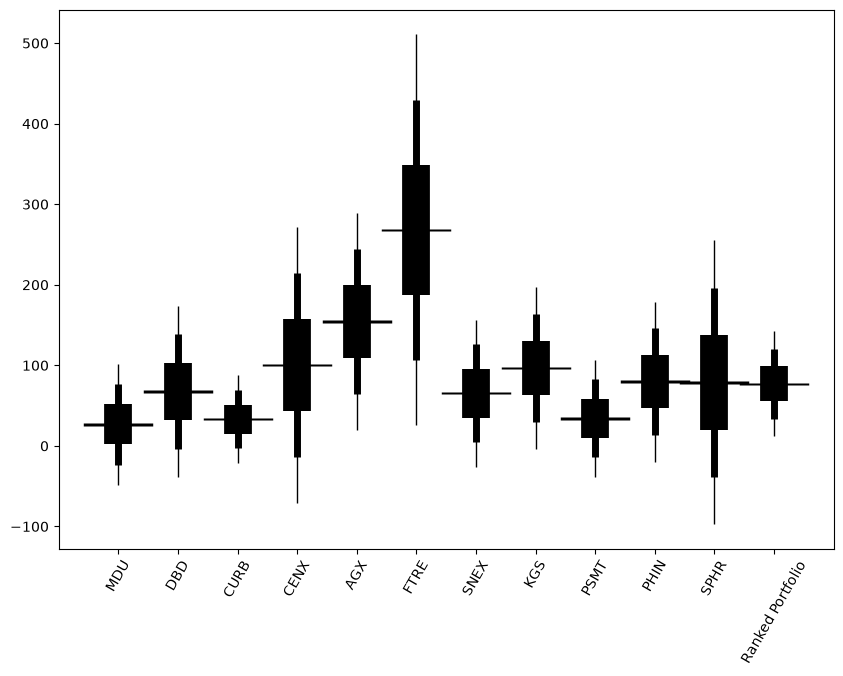

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

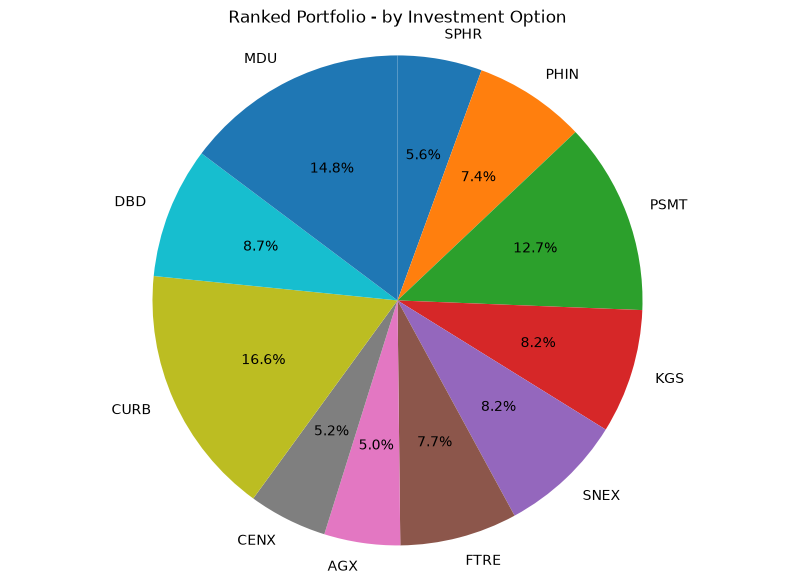

SPHR   0.06
PHIN   0.07
PSMT   0.13
KGS    0.08
SNEX   0.08
FTRE   0.08
AGX    0.05
CENX   0.05
CURB   0.17
DBD    0.09
MDU    0.15



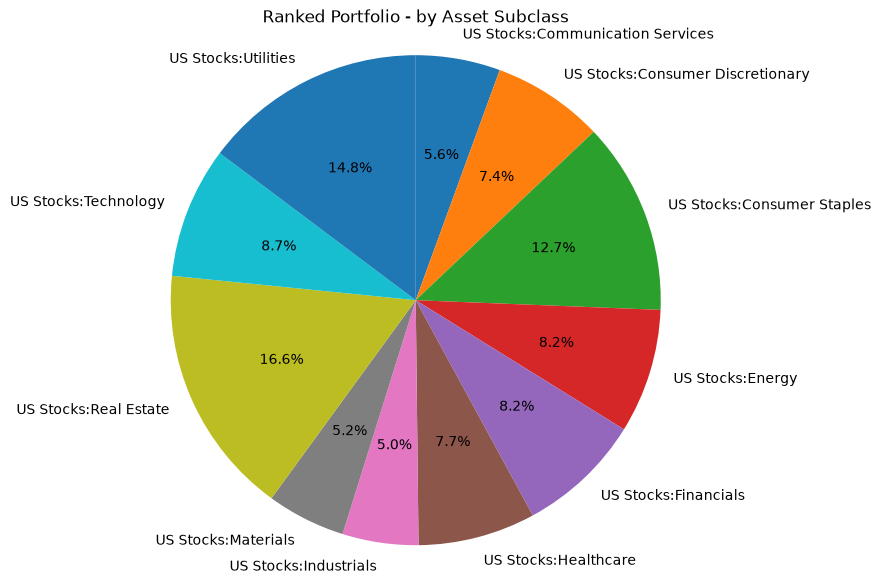

US Stocks:Communication Services   0.06
US Stocks:Consumer Discretionary   0.07
US Stocks:Consumer Staples         0.13
US Stocks:Energy                   0.08
US Stocks:Financials               0.08
US Stocks:Healthcare               0.08
US Stocks:Industrials              0.05
US Stocks:Materials                0.05
US Stocks:Real Estate              0.17
US Stocks:Technology               0.09
US Stocks:Utilities                0.15



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Subclass'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Ranked Portfolio Weights:
    MDU                            0.1475
    DBD                            0.0866
    CURB                           0.1657
    CENX                           0.0519
    AGX                            0.0501
    FTRE                           0.0775
    SNEX                           0.0824
    KGS                            0.0821
    PSMT                           0.1269
    PHIN                           0.0737
    SPHR                           0.0557


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).